# Evidencia 2 – Equipo 3 · Atlantic Data Consulting
**Sistema de recomendación DanuStore: segmentación (GMM) + recomendación (mejoras del modelo, Etapa 6.2)**

Alfredo Arriaga Morales · Baruch Fernando Aviles Flores · Génesis Vázquez Hernández · Julián Stanis Nolasco Martínez · Misael Pedraza Uribe

## 1. Librerías y configuración

In [ ]:
# 1. Libreria y configuración
import os, glob                                                    # búsqueda de archivos
import warnings                                                    # ocultar avisos de formato de fecha
warnings.filterwarnings('ignore', category=UserWarning)
import numpy as np                                                 # cálculo numérico
import pandas as pd                                                # manejo de tablas
import matplotlib.pyplot as plt                                    # gráficas
from scipy.stats import rankdata                                   # rangos para ROC-AUC vectorizado
from scipy.stats import kruskal, chi2_contingency, wilcoxon        # pruebas estadísticas de respaldo
from sklearn.preprocessing import StandardScaler                   # estandarización z-score
from sklearn.mixture import GaussianMixture                        # Modelo 1: segmentación
from sklearn.cluster import DBSCAN                                 # apoyo: detección de atípicos
from sklearn.decomposition import TruncatedSVD                     # Modelo 2: recomendación
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score                    # estabilidad de los segmentos

pd.set_option('display.max_columns', 50)                           # ver todas las columnas
pd.set_option('display.float_format', '{:,.4f}'.format)            # 4 decimales en tablas

SEMILLA = 42                                                       # reproducibilidad
VENTANA_DIAS = 30                                                  # días que se observan después de cada corte
TOP_N = 3                                                          # productos recomendados por cliente
K_SEGMENTOS = 4                                                    # segmentos del GMM (justificado en 5.5: codo del BIC + estabilidad)
COVARIANZA = 'spherical'                                           # tipo de covarianza del GMM (comparado en 5.5)
VARS_RFM = ['recencia_dias', 'num_transacciones', 'gasto_total']   # variables del GMM

CORTE_VALIDACION = '2025-04-25'                                    # 1) corte para ajustar hiperparámetros de cada modelo
CORTE_SELECCION = '2025-05-25'                                     # 2) corte para elegir el sistema final (distinto al de ajuste)
CORTES_EVALUACION = ['2025-06-24', '2025-07-24', '2025-08-23',     # 3) cortes reservados: solo se usan para reportar resultados
                     '2025-09-22', '2025-10-22']                   # (el primero es el mismo corte del piloto de Misael)

GRID_FACTORES = [5, 10, 20, 30]                                    # factores latentes que se prueban en el SVD
GRID_ALFA = [0, 0.25, 0.5, 0.75, 1]                                # peso de la popularidad (0 = SVD puro, 1 = solo popularidad)

GRID_TAU = [None, 180, 90, 30]                                     # vida media del peso por antigüedad (días); None = todas las compras pesan igual
GRID_LAMBDA = [10, 50, 200, 1000]                                  # regularización de EASE (más alto = más suave)
GRID_BETA = [0, 0.25, 0.5, 0.75]                                   # peso del historial personal al combinarlo con EASE

MODELOS = ['Mejor por segmento', 'EASE + historial', 'EASE',       # candidatos a sistema final (nuevos)
           'kNN de productos', 'Historial personal',
           'Híbrido por clúster', 'SVD por clúster',               # (Evidencia 2)
           'Híbrido global', 'SVD global']
REFERENCIAS = ['Populares por segmento', 'Populares (global)', 'Aleatorio']   # líneas base
METODOS = MODELOS + REFERENCIAS

ORDEN_SEG = ['VIP', 'Regulares', 'Ocasionales', 'Inactivos']       # orden de presentación
COLORES = {'VIP': '#1f4e79', 'Regulares': '#7a9e3a', 'Ocasionales': '#e07b39', 'Inactivos': '#9c9c9c'}

## 2. Carga de datos

In [ ]:
# 2. Carga de datos
# Archivos necesarios: ventas (uno o varios .csv/.xlsx con "sale" o "venta" en el nombre) y products (.csv/.xlsx)
# base_final_final_final_1.csv (solo para validar los segmentos contra segmento_cliente)
try:
    from google.colab import files                                 # en Colab se suben los archivos
    if not glob.glob('*sale*') and not glob.glob('*venta*'):
        files.upload()                                             # seleccionar ventas, products y (opcional) base final
except ImportError:
    pass                                                           # fuera de Colab se leen de la carpeta actual

def leer(ruta):
    # lee csv o excel; si el csv no está en UTF-8 lo intenta con latin-1
    if not ruta.lower().endswith('.csv'):
        return pd.read_excel(ruta)
    try:
        return pd.read_csv(ruta, encoding='utf-8', low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(ruta, encoding='latin-1', low_memory=False)

rutas_ventas = sorted(set(glob.glob('*sale*') + glob.glob('*Sale*') + glob.glob('*venta*') + glob.glob('*Venta*')))
rutas_ventas = [r for r in rutas_ventas if r.lower().endswith(('.csv', '.xlsx'))]
ventas_por_archivo = {r: leer(r) for r in rutas_ventas}                     # cada archivo por separado
productos = leer(glob.glob('*product*')[0])                                  # catálogo de productos
rutas_base = glob.glob('base_final*')                                        # base integrada (opcional)
base = leer(rutas_base[0]) if rutas_base else None

for r, v in ventas_por_archivo.items():
    print(f'{r}: {v.shape} | columnas: {list(v.columns)}')                   # revisar que cada archivo tenga sus columnas
print('Productos:', productos.shape, '| Base final:', None if base is None else base.shape)

Saving products.csv to products.csv
Saving sales.csv to sales.csv
Saving sales_2024.csv to sales_2024.csv
Saving base_final_final_final.csv to base_final_final_final.csv
sales.csv: (1200000, 7) | columnas: ['transaction_id', 'date', 'client_id', 'region', 'product_id', 'units_sold', 'sales_amount']
sales_2024.csv: (1048575, 7) | columnas: ['transaction_id', 'date', 'client_id', 'region', 'product_id', 'units_sold', 'sales_amount']
Productos: (130, 9) | Base final: (45000, 25)


## 3. Limpieza y estandarización de ventas

In [ ]:
# 3. Limpieza y estadarización de ventas
def buscar(df, opciones, obligatoria=True):
    # devuelve la primera columna cuyo nombre contiene alguna de las opciones (sin importar mayúsculas)
    for op in opciones:
        for c in df.columns:
            if op in str(c).lower().strip():
                return c
    if obligatoria:
        raise KeyError(f'No se encontró columna para {opciones}: {list(df.columns)}')
    return None

def a_fecha(serie):
    # convierte a fecha probando formato año-mes-día y día/mes/año; se queda con el que tenga menos vacíos
    f1 = pd.to_datetime(serie, errors='coerce')
    if f1.isna().mean() < 0.01:
        return f1.dt.normalize()
    f2 = pd.to_datetime(serie, errors='coerce', dayfirst=True)
    return (f2 if f2.isna().sum() < f1.isna().sum() else f1).dt.normalize()

def a_numero(serie):
    # convierte a número aunque venga como texto con $ o comas
    if serie.dtype == object:
        serie = serie.astype(str).str.replace(r'[$,\s]', '', regex=True)
    return pd.to_numeric(serie, errors='coerce')

precio_cat = productos.set_index('product_id')['static_price']             # precio de catálogo

def estandarizar(v, archivo):
    # detecta las columnas de UN archivo y lo lleva al formato común
    c = dict(cliente=buscar(v, ['client_id', 'cliente_id', 'customer', 'cliente', 'client']),
             producto=buscar(v, ['product_id', 'producto_id', 'product', 'producto']),
             fecha=buscar(v, ['date', 'fecha']),
             cantidad=buscar(v, ['units', 'quantity', 'cantidad', 'qty', 'unidades'], obligatoria=False),
             monto=buscar(v, ['sales', 'total', 'amount', 'revenue', 'monto', 'importe'], obligatoria=False),
             transaccion=buscar(v, ['transaction', 'sale_id', 'order', 'ticket', 'transaccion', 'venta_id'], obligatoria=False))
    if c['monto'] in (c['cliente'], c['producto'], c['fecha'], c['transaccion']):
        c['monto'] = None                                                  # evita confundir 'sales_id' con monto
    print(f'{archivo} -> {c}')
    t = pd.DataFrame({'cliente_id': a_numero(v[c['cliente']]),
                      'product_id': a_numero(v[c['producto']]),
                      'fecha': a_fecha(v[c['fecha']])})
    t['cantidad'] = a_numero(v[c['cantidad']]) if c['cantidad'] else 1      # 1 si no hay cantidad
    t['monto'] = a_numero(v[c['monto']]) if c['monto'] else t['cantidad'] * t['product_id'].map(precio_cat)
    t['transaccion'] = v[c['transaccion']].astype(str).values if c['transaccion'] else np.nan
    t['archivo'] = archivo
    return t

ventas = pd.concat([estandarizar(v, r) for r, v in ventas_por_archivo.items()], ignore_index=True)

# 3.1 Limpieza
n0 = len(ventas)
ventas = ventas.dropna(subset=['cliente_id', 'product_id', 'fecha'])                 # registros sin llave o fecha
ventas = ventas[ventas['product_id'].isin(productos['product_id'])]                  # solo productos del catálogo
ventas = ventas[(ventas['cantidad'] > 0) & (ventas['monto'] > 0)]                    # cantidades y montos válidos
ventas[['cliente_id', 'product_id']] = ventas[['cliente_id', 'product_id']].astype(int)
sin_trans = ventas['transaccion'].isna()
ventas.loc[sin_trans, 'transaccion'] = (ventas.loc[sin_trans, 'cliente_id'].astype(str) + '_' +
                                        ventas.loc[sin_trans, 'fecha'].dt.strftime('%Y%m%d'))   # 1 visita = cliente + día
ventas = ventas.drop_duplicates(subset=['cliente_id', 'product_id', 'fecha', 'cantidad', 'monto', 'transaccion'])  # duplicados

# 3.2 Revisión por archivo: cuántas filas sobreviven y qué periodo cubre cada uno
revision = ventas.groupby('archivo').agg(filas_validas=('fecha', 'size'), desde=('fecha', 'min'), hasta=('fecha', 'max'))
revision.insert(0, 'filas_originales', pd.Series({r: len(v) for r, v in ventas_por_archivo.items()}))
display(revision)

print(f'Registros: {n0:,} -> {len(ventas):,} después de limpieza')
print('Periodo:', ventas['fecha'].min().date(), 'a', ventas['fecha'].max().date())
print('Clientes:', ventas['cliente_id'].nunique(), '| Productos:', ventas['product_id'].nunique())

PRODUCTOS = np.sort(productos['product_id'].unique())                               # columnas de la matriz cliente × producto
FECHA_MAX = ventas['fecha'].max()
CORTES_EVALUACION = [c for c in CORTES_EVALUACION                                    # solo cortes con ventana completa
                     if pd.Timestamp(c) + pd.Timedelta(days=VENTANA_DIAS) <= FECHA_MAX + pd.Timedelta(days=1)]
print('Cortes de evaluación válidos:', CORTES_EVALUACION)

sales.csv -> {'cliente': 'client_id', 'producto': 'product_id', 'fecha': 'date', 'cantidad': 'units_sold', 'monto': 'sales_amount', 'transaccion': 'transaction_id'}
sales_2024.csv -> {'cliente': 'client_id', 'producto': 'product_id', 'fecha': 'date', 'cantidad': 'units_sold', 'monto': 'sales_amount', 'transaccion': 'transaction_id'}


,filas_originales,filas_validas,desde,hasta
archivo,,,,
sales.csv,1200000,1200000,2025-01-01,2025-12-31
sales_2024.csv,1048575,1044587,2024-01-01,2024-12-31


Registros: 2,248,575 -> 2,244,587 después de limpieza
Periodo: 2024-01-01 a 2025-12-31
Clientes: 44987 | Productos: 130
Cortes de evaluación válidos: ['2025-06-24', '2025-07-24', '2025-08-23', '2025-09-22', '2025-10-22']


## 4. Funciones del sistema

In [ ]:
# 4. Funciones del sistema
# Todo se calcula SOLO con compras anteriores al corte -> sin fuga temporal

def rfm(ventas_hist, corte):
    # variables RFM por cliente con historial anterior al corte
    g = ventas_hist.groupby('cliente_id')
    t = pd.DataFrame({
        'recencia_dias': (corte - g['fecha'].max()).dt.days,          # días desde la última compra
        'num_transacciones': g['transaccion'].nunique(),              # compras distintas
        'gasto_total': g['monto'].sum(),                              # gasto acumulado
    })
    return t

def segmentar(t, k=K_SEGMENTOS, cov=None):
    # Modelo 1: GMM sobre RFM estandarizado + nombre de cada segmento
    cov = cov or COVARIANZA
    scaler = StandardScaler()
    X = scaler.fit_transform(t[VARS_RFM])
    gmm = GaussianMixture(n_components=k, covariance_type=cov, n_init=3, random_state=SEMILLA).fit(X)
    t = t.copy()
    t['cluster'] = gmm.predict(X)
    t['prob_segmento'] = gmm.predict_proba(X).max(axis=1)             # confianza de la asignación
    perfil = t.groupby('cluster')[VARS_RFM].mean()
    inactivo = perfil['recencia_dias'].idxmax()                       # más días sin comprar
    resto = perfil.drop(inactivo)['gasto_total'].sort_values(ascending=False).index
    nombres = {inactivo: 'Inactivos', resto[0]: 'VIP', resto[1]: 'Regulares', resto[2]: 'Ocasionales'}
    t['segmento'] = t['cluster'].map(nombres)
    return t, gmm, scaler, X

def matriz(ventas_hist, clientes):
    # matriz cliente × producto: días distintos de compra, con log1p para suavizar frecuencias altas
    m = (ventas_hist.groupby(['cliente_id', 'product_id'])['fecha'].nunique()
         .unstack(fill_value=0).reindex(index=clientes, columns=PRODUCTOS, fill_value=0))
    return np.log1p(m.values.astype(float))

def puntajes_svd(M, n_factores):
    # Modelo 2: SVD truncado -> reconstrucción de la matriz = puntaje de afinidad cliente-producto
    n_factores = min(n_factores, M.shape[0] - 1, M.shape[1] - 1)  # no más factores que filas o columnas
    svd = TruncatedSVD(n_components=n_factores, random_state=SEMILLA)
    U = svd.fit_transform(M)
    return U @ svd.components_

def puntajes_populares(M, grupos=None):
    # referencia: popularidad global o popularidad dentro del grupo (segmento)
    if grupos is None:
        return np.tile((M > 0).sum(axis=0), (M.shape[0], 1)).astype(float)
    S = np.zeros_like(M)
    for g in np.unique(grupos):
        idx = grupos == g
        S[idx] = (M[idx] > 0).sum(axis=0)                             # popularidad del segmento
    return S

def puntajes_aleatorios(M):
    # referencia mínima: productos al azar (lo que obtendría un sistema sin ningún aprendizaje)
    return np.random.default_rng(SEMILLA).random(M.shape)

def rango_fila(S):
    # convierte puntajes a rango 0-1 dentro de cada cliente (hace comparables SVD y popularidad)
    return rankdata(S, axis=1) / S.shape[1]

def puntajes_hibrido(S_svd, S_pop, alfa):
    # combina afinidad personal (SVD) con popularidad (alfa = peso de la popularidad)
    return (1 - alfa) * rango_fila(S_svd) + alfa * rango_fila(S_pop)

def puntajes_por_cluster(M, grupos, params):
    # Modelo 2 por clúster: un SVD distinto entrenado SOLO con los clientes de cada segmento del GMM
    # params = {segmento: (n_factores, alfa)} elegidos por segmento en el corte de validación
    S = np.zeros_like(M, dtype=float)
    for s in np.unique(grupos):
        idx = grupos == s
        f, a = params[s]
        S_svd = puntajes_svd(M[idx], f)                               # factores aprendidos dentro del segmento
        S_pop = puntajes_populares(M[idx])                            # popularidad dentro del segmento
        S[idx] = puntajes_hibrido(S_svd, S_pop, a)
    return S

def contexto(hist, corte, clientes, seg, t=None):
    # todo lo que un modelo necesita en un corte: historial, matriz base, segmentos y caché de matrices/puntajes
    M = matriz(hist, clientes)
    return {'hist': hist, 'corte': corte, 'clientes': clientes, 'seg': seg, 't': t, 'M': M, 'X': {None: M}, 'S': {}}

def matriz_decay(hist, clientes, corte, tau):
    # matriz cliente × producto donde cada día de compra pesa 0.5^(antigüedad / tau): lo reciente cuenta más
    d = hist[['cliente_id', 'product_id', 'fecha']].drop_duplicates()
    d = d.assign(peso=0.5 ** ((corte - d['fecha']).dt.days / tau))
    m = (d.groupby(['cliente_id', 'product_id'])['peso'].sum()
         .unstack(fill_value=0).reindex(index=clientes, columns=PRODUCTOS, fill_value=0))
    return np.log1p(m.values.astype(float))

def X_tau(ctx, tau):
    # matriz con decaimiento tau (se calcula una sola vez por corte)
    if tau not in ctx['X']:
        ctx['X'][tau] = matriz_decay(ctx['hist'], ctx['clientes'], ctx['corte'], tau)
    return ctx['X'][tau]

def puntajes_ease(X, lam):
    # EASE (Steck, 2019): aprende cuánto "empuja" cada producto a cada otro producto; solución cerrada en una sola fórmula
    G = X.T @ X                                                       # coocurrencias producto × producto
    G[np.diag_indices_from(G)] += lam                                 # regularización
    P = np.linalg.inv(G)
    B = -P / np.diag(P)                                               # pesos producto -> producto
    B[np.diag_indices_from(B)] = 0                                    # un producto no se recomienda a sí mismo por esta vía
    return X @ B

def puntajes_knn(X):
    # filtrado colaborativo por productos: similitud coseno entre productos según quién los compra
    norma = np.linalg.norm(X, axis=0)
    norma[norma == 0] = 1
    S = (X / norma).T @ (X / norma)                                   # similitud producto × producto
    np.fill_diagonal(S, 0)
    return X @ S

def puntajes_historial(X):
    # referencia fuerte de retail: volver a ofrecer lo que el cliente ya compra (desempate con popularidad)
    return X + 1e-6 * (X > 0).sum(axis=0)

def puntajes_metodo(nombre, ctx):
    # calcula (y guarda en caché) los puntajes de cualquier método evaluado
    if nombre in ctx['S']:
        return ctx['S'][nombre]
    M, seg = ctx['M'], ctx['seg']
    if nombre == 'Mejor por segmento':                                # cada segmento usa el modelo que mejor le funcionó en validación
        S = np.zeros_like(M, dtype=float)
        for s, metodo in RUTA.items():
            idx = seg == s
            S[idx] = rango_fila(puntajes_metodo(metodo, ctx)[idx])
    elif nombre == 'EASE + historial':
        S = puntajes_hibrido(puntajes_metodo('EASE', ctx), puntajes_metodo('Historial personal', ctx), BETA)
    elif nombre == 'EASE':
        S = puntajes_ease(X_tau(ctx, P_EASE['tau']), P_EASE['lam'])
    elif nombre == 'kNN de productos':
        S = puntajes_knn(X_tau(ctx, P_KNN['tau']))
    elif nombre == 'Historial personal':
        S = puntajes_historial(X_tau(ctx, P_HIST['tau']))
    elif nombre == 'Híbrido por clúster':
        S = puntajes_por_cluster(M, seg, PARAMS_CLUSTER)
    elif nombre == 'SVD por clúster':
        S = puntajes_por_cluster(M, seg, PARAMS_SVD_CLUSTER)
    elif nombre == 'Híbrido global':
        S = puntajes_hibrido(puntajes_svd(M, N_FACTORES), puntajes_populares(M, seg), ALFA)
    elif nombre == 'SVD global':
        S = puntajes_svd(M, N_FACTORES_SVD)
    elif nombre == 'Populares por segmento':
        S = puntajes_populares(M, seg)
    elif nombre == 'Populares (global)':
        S = puntajes_populares(M)
    elif nombre == 'Aleatorio':
        S = puntajes_aleatorios(M)
    else:
        raise ValueError(nombre)
    ctx['S'][nombre] = S
    return S

def top_n(S, n=TOP_N):
    # índices de los n productos con mayor puntaje por cliente
    return np.argsort(-S, axis=1)[:, :n]

def evaluar(S, Y, solo_compradores=True, detalle=False):
    # métricas top-N; Y = compras reales en la ventana (0/1)
    # solo_compradores=True: se evalúa solo a quien compró en la ventana (si no compró, ninguna recomendación puede acertar)
    top = top_n(S)
    aciertos = np.take_along_axis(Y, top, axis=1).sum(axis=1)
    positivos = Y.sum(axis=1)
    ev = positivos > 0 if solo_compradores else np.ones(len(Y), dtype=bool)
    if ev.sum() == 0:
        return ({}, np.array([])) if detalle else {}
    a, p = aciertos[ev], positivos[ev]
    precision = a / TOP_N
    recall = np.divide(a, p, out=np.zeros_like(a, dtype=float), where=p > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros_like(precision), where=(precision + recall) > 0)
    # ROC-AUC por cliente (vectorizado con rangos), solo clientes con positivos y negativos
    ok = (positivos > 0) & (positivos < Y.shape[1])
    R = rankdata(S[ok], axis=1)
    P, N = positivos[ok], Y.shape[1] - positivos[ok]
    auc = ((R * Y[ok]).sum(axis=1) - P * (P + 1) / 2) / (P * N)
    met = {'Precision@3': precision.mean(), 'Recall@3': recall.mean(), 'F1@3': f1.mean(),
           'Tasa_acierto': (a > 0).mean(), 'ROC_AUC_cliente': auc.mean() if ok.any() else np.nan,
           'clientes_evaluados': int(ev.sum())}
    return (met, a) if detalle else met

def preparar_corte(corte):
    # historial antes del corte, segmentos (GMM), contexto de modelos y compras reales de la ventana siguiente
    corte = pd.Timestamp(corte)
    hist = ventas[ventas['fecha'] < corte]
    fut = ventas[(ventas['fecha'] >= corte) & (ventas['fecha'] < corte + pd.Timedelta(days=VENTANA_DIAS))]
    t, *_ = segmentar(rfm(hist, corte))
    clientes = t.index.values
    ctx = contexto(hist, corte, clientes, t['segmento'].values, t)
    Y = (matriz(fut, clientes) > 0).astype(int)
    return ctx, Y

## 5. Modelo 1 – Segmentación con GMM (corte principal)

In [ ]:
# 5. Modelo 1: segmentación GMM en el corte principal
corte0 = pd.Timestamp(CORTES_EVALUACION[0])
hist0 = ventas[ventas['fecha'] < corte0]                                  # solo compras anteriores al corte
rfm0 = rfm(hist0, corte0)
print(f'Clientes con historial antes de {corte0.date()}: {len(rfm0):,}')
print('Correlación entre variables RFM:')
display(rfm0.corr(method='spearman').round(2))

# 5.1 Número de componentes: BIC y Silhouette (muestra de 10,000 para Silhouette)
X0 = StandardScaler().fit_transform(rfm0[VARS_RFM])
rng = np.random.default_rng(SEMILLA)
idx_m = rng.choice(len(X0), size=min(10000, len(X0)), replace=False)
filas = []
for k in range(2, 8):
    g = GaussianMixture(n_components=k, covariance_type=COVARIANZA, n_init=3, random_state=SEMILLA).fit(X0)
    filas.append({'k': k, 'BIC': g.bic(X0), 'Silhouette': silhouette_score(X0[idx_m], g.predict(X0[idx_m]))})
sel_k = pd.DataFrame(filas).set_index('k')
display(sel_k.round(3))

Clientes con historial antes de 2025-06-24: 44,981
Correlación entre variables RFM:


,recencia_dias,num_transacciones,gasto_total
recencia_dias,1.0000,-0.4000,-0.3400
num_transacciones,-0.4000,1.0000,0.8400
gasto_total,-0.3400,0.8400,1.0000


,BIC,Silhouette
k,,
2,"355,198.7500",0.3740
3,"325,219.6890",0.3800
4,"311,495.9570",0.3250
5,"304,473.6470",0.3220
6,"298,890.4880",0.2850
7,"295,084.4430",0.2950


Silhouette (muestra): 0.325 | Calinski-Harabasz: 35376.4 | Davies-Bouldin: 0.944 | Confianza media: 0.882


,clientes,recencia_dias,num_transacciones,gasto_total,prob_segmento,%_clientes,%_gasto
segmento,,,,,,,
VIP,6829,22.1000,19.2000,"8,327.1000",0.9000,15.2000,27.3000
Regulares,17414,26.9000,13.6000,"5,275.9000",0.9000,38.7000,44.0000
Ocasionales,14174,33.1000,8.5000,"2,951.0000",0.9000,31.5000,20.0000
Inactivos,6564,127.3000,7.3000,"2,756.3000",0.9000,14.6000,8.7000


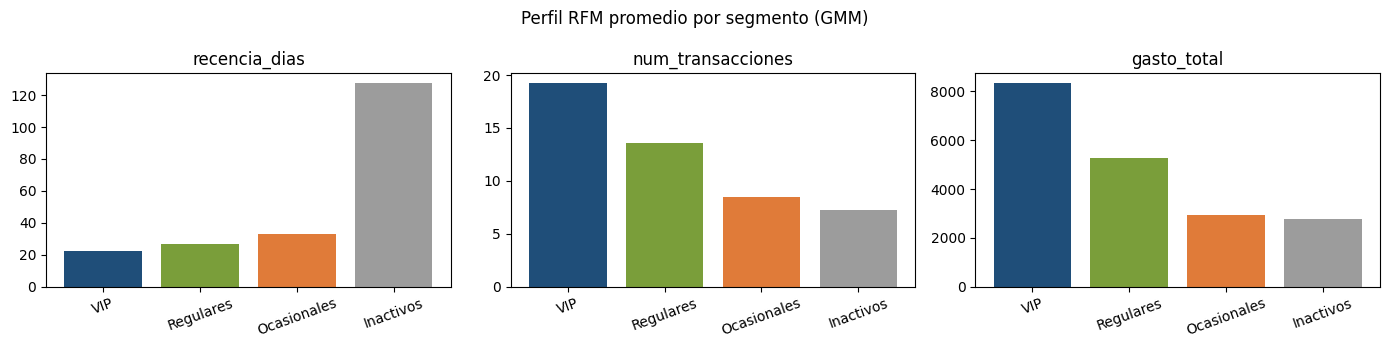

In [ ]:
# 5.2 Modelo final del corte principal (k = 4) y métricas internas
seg0, gmm0, scaler0, Xs0 = segmentar(rfm0)
etq0 = seg0['cluster'].values
print('Silhouette (muestra):', round(silhouette_score(Xs0[idx_m], etq0[idx_m]), 3),
      '| Calinski-Harabasz:', round(calinski_harabasz_score(Xs0, etq0), 1),
      '| Davies-Bouldin:', round(davies_bouldin_score(Xs0, etq0), 3),
      '| Confianza media:', round(seg0['prob_segmento'].mean(), 3))

# 5.3 Perfil de cada segmento
perfil0 = seg0.groupby('segmento').agg(clientes=('cluster', 'size'),
                                       recencia_dias=('recencia_dias', 'mean'),
                                       num_transacciones=('num_transacciones', 'mean'),
                                       gasto_total=('gasto_total', 'mean'),
                                       prob_segmento=('prob_segmento', 'mean')).loc[ORDEN_SEG]
perfil0['%_clientes'] = perfil0['clientes'] / perfil0['clientes'].sum() * 100
perfil0['%_gasto'] = seg0.groupby('segmento')['gasto_total'].sum().loc[ORDEN_SEG] / seg0['gasto_total'].sum() * 100
display(perfil0.round(1))

# 5.4 Gráfica del perfil (cada variable normalizada a su máximo)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, v in zip(ax, VARS_RFM):
    a.bar(ORDEN_SEG, perfil0[v], color=[COLORES[s] for s in ORDEN_SEG])
    a.set_title(v)
    a.tick_params(axis='x', rotation=20)
plt.suptitle('Perfil RFM promedio por segmento (GMM)')
plt.tight_layout()
plt.show()

,BIC,Silhouette,Mejora_BIC,Mejora_%
k,,,,
2,"355,198.7500",0.3740,NaN,NaN
3,"325,219.6890",0.3800,"29,979.0610",8.4400
4,"311,495.9570",0.3250,"13,723.7320",4.2200
5,"304,473.6470",0.3220,"7,022.3100",2.2540
6,"298,890.4880",0.2850,"5,583.1590",1.8340
7,"295,084.4430",0.2950,"3,806.0450",1.2730


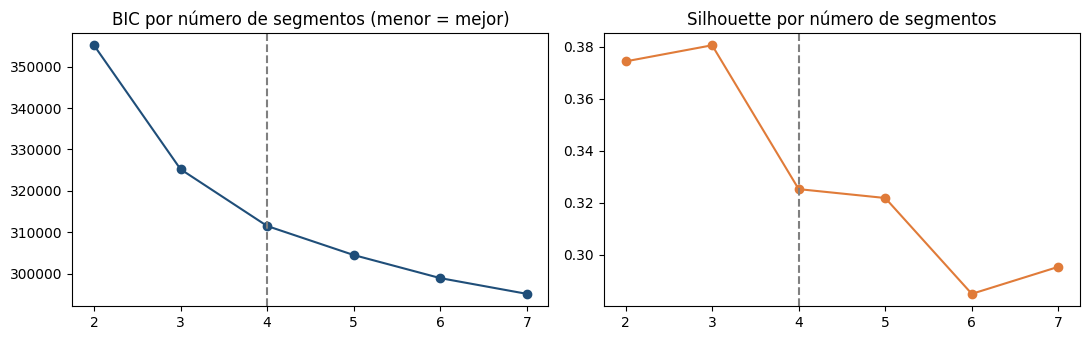

,ARI_medio,ARI_minimo
k,,
3,0.9910,0.9860
4,0.9720,0.9540
5,0.9830,0.9810


,parametros,BIC,Silhouette
covarianza,,,
spherical,19,"311,495.9570",0.3250
diag,27,"299,180.8280",0.2460
tied,21,"298,261.3360",0.2830
full,39,"277,259.7960",0.1330


Menor BIC: full | Mayor Silhouette: spherical | Usada: spherical


,grupo_k3_0,grupo_k3_1,grupo_k3_2
segmento,,,
VIP,100.0000,0.0000,0.0000
Regulares,45.6000,0.0000,54.4000
Ocasionales,0.0000,2.2000,97.8000
Inactivos,1.6000,90.3000,8.1000


In [ ]:
# 5.5 Justificación del número de segmentos (k) y del tipo de covarianza
# a) Codo del BIC: cuánto baja el BIC al agregar un segmento (el codo está donde la mejora se reduce a la mitad)
sel_k['Mejora_BIC'] = -sel_k['BIC'].diff()                                 # mejora absoluta respecto a k-1
sel_k['Mejora_%'] = sel_k['Mejora_BIC'] / sel_k['BIC'].shift() * 100        # mejora relativa
display(sel_k.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(sel_k.index, sel_k['BIC'], marker='o', color='#1f4e79')
ax[0].axvline(K_SEGMENTOS, ls='--', color='gray')
ax[0].set_title('BIC por número de segmentos (menor = mejor)')
ax[1].plot(sel_k.index, sel_k['Silhouette'], marker='o', color='#e07b39')
ax[1].axvline(K_SEGMENTOS, ls='--', color='gray')
ax[1].set_title('Silhouette por número de segmentos')
plt.tight_layout()
plt.show()

# b) Estabilidad: se reentrena con 5 submuestras del 80% y se compara con el modelo completo (ARI: 1 = mismos grupos)
filas = []
for k in [3, 4, 5]:
    ref = GaussianMixture(n_components=k, covariance_type=COVARIANZA, n_init=3, random_state=SEMILLA).fit(X0)
    etq_ref = ref.predict(X0[idx_m])                                        # etiquetas de referencia en la muestra
    aris = []
    for b in range(5):
        sub = rng.choice(len(X0), size=int(0.8 * len(X0)), replace=False)  # submuestra del 80%
        g = GaussianMixture(n_components=k, covariance_type=COVARIANZA, n_init=3, random_state=b).fit(X0[sub])
        aris.append(adjusted_rand_score(etq_ref, g.predict(X0[idx_m])))
    filas.append({'k': k, 'ARI_medio': np.mean(aris), 'ARI_minimo': np.min(aris)})
estabilidad = pd.DataFrame(filas).set_index('k')
display(estabilidad.round(3))

# c) Tipo de covarianza con k = K_SEGMENTOS (más parámetros = modelo más flexible pero más difícil de interpretar)
filas = []
for cov in ['spherical', 'diag', 'tied', 'full']:
    g = GaussianMixture(n_components=K_SEGMENTOS, covariance_type=cov, n_init=3, random_state=SEMILLA).fit(X0)
    filas.append({'covarianza': cov, 'parametros': g._n_parameters(), 'BIC': g.bic(X0),
                  'Silhouette': silhouette_score(X0[idx_m], g.predict(X0[idx_m]))})
tabla_cov = pd.DataFrame(filas).set_index('covarianza')
display(tabla_cov.round(3))
print('Menor BIC:', tabla_cov['BIC'].idxmin(), '| Mayor Silhouette:', tabla_cov['Silhouette'].idxmax(),
      '| Usada:', COVARIANZA)

# d) ¿Qué se pierde con k = 3? Cruce de los 3 grupos contra los 4 segmentos (% de cada segmento)
g3 = GaussianMixture(n_components=3, covariance_type=COVARIANZA, n_init=3, random_state=SEMILLA).fit(X0)
cruce_k3 = pd.crosstab(seg0['segmento'], g3.predict(X0), normalize='index').loc[ORDEN_SEG] * 100
cruce_k3.columns = [f'grupo_k3_{c}' for c in cruce_k3.columns]
display(cruce_k3.round(1))

## 6. Apoyo – Detección de atípicos con DBSCAN

In [ ]:
# 6. DBSCAN como detector de atipicos ====
# eps = 0.4 y min_samples = 10 (elegidos con la gráfica k-distancia en el avance individual)
db = DBSCAN(eps=0.4, min_samples=10).fit(Xs0)
seg0['atipico'] = db.labels_ == -1                                         # ruido = cliente atípico
print(f"Clientes atípicos: {seg0['atipico'].sum():,} ({seg0['atipico'].mean() * 100:.2f}%)")
display(seg0.groupby('atipico')[VARS_RFM].mean().round(1))
display(pd.crosstab(seg0['segmento'], seg0['atipico']).loc[ORDEN_SEG])

Clientes atípicos: 96 (0.21%)


,recencia_dias,num_transacciones,gasto_total
atipico,,,
False,42.7000,11.9000,"4,626.3000"
True,75.6000,20.3000,"10,481.8000"


atipico,False,True
segmento,,
VIP,6757,72
Regulares,17414,0
Ocasionales,14171,3
Inactivos,6543,21


## 7. Validación estadística de los segmentos

In [ ]:
# 7. Validación estadística de los segmentos
# Se usa la segmentación con TODO el historial: misma fecha de referencia que segmento_cliente de la base final
seg_v, *_ = segmentar(rfm(ventas, FECHA_MAX + pd.Timedelta(days=1)))
print('Clientes por segmento:', seg_v['segmento'].value_counts().loc[ORDEN_SEG].to_dict())

# 7.1 ¿Los segmentos son distintos en RFM? Kruskal-Wallis (no supone normalidad) + tamaño de efecto épsilon²
filas = []
for v in VARS_RFM:
    H, p = kruskal(*[seg_v.loc[seg_v['segmento'] == s, v] for s in ORDEN_SEG])
    filas.append({'variable': v, 'H': H, 'p_valor': p, 'epsilon2': H / (len(seg_v) - 1)})   # épsilon² > 0.26 = efecto grande
display(pd.DataFrame(filas).set_index('variable'))

# 7.2 Asociación de los segmentos con variables de la base final: Chi-cuadrada + V de Cramér (Bonferroni)
def cramer_v(tabla):
    chi2, p, gl, _ = chi2_contingency(tabla)
    return chi2, p, gl, np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))

COLS_BASE = ['segmento_cliente', 'uso_descuentos', 'categoria_cliente', 'canal_preferido', 'categoria_favorita',
             'nivel_socioeconomico', 'zona_geografica', 'genero', 'grupo_edad', 'ocupacion']
if base is not None and 'cliente_id' in base.columns:
    cols = [c for c in COLS_BASE if c in base.columns]                      # solo las variables categóricas que existen en la base
    bv = seg_v.join(base.set_index('cliente_id')[cols], how='inner')        # se traen solo esas columnas (la base también tiene recencia, etc.)
    filas = []
    for col in cols:
        chi2, p, gl, V = cramer_v(pd.crosstab(bv['segmento'], bv[col]))
        filas.append({'variable': col, 'chi2': chi2, 'gl': gl, 'p_valor': p, 'V_Cramer': V,
                      'significativa': p < 0.05 / len(cols)})               # corrección de Bonferroni
    asociaciones = pd.DataFrame(filas).set_index('variable').sort_values('V_Cramer', ascending=False)
    display(asociaciones.round(4))

    # 7.3 Tablas que respaldan la interpretación y las campañas (% por fila)
    for col in ['segmento_cliente', 'uso_descuentos']:
        if col in bv.columns:
            display((pd.crosstab(bv['segmento'], bv[col], normalize='index').loc[ORDEN_SEG] * 100).round(1))
else:
    print('No se cargó base_final_final_final_1.csv: se omite la validación externa.')

Clientes por segmento: {'VIP': 7434, 'Regulares': 17834, 'Ocasionales': 14267, 'Inactivos': 5452}


,H,p_valor,epsilon2
variable,,,
recencia_dias,"15,025.0794",0.0000,0.3340
num_transacciones,"33,385.1613",0.0000,0.7421
gasto_total,"32,662.7794",0.0000,0.7261


,chi2,gl,p_valor,V_Cramer,significativa
variable,,,,,
segmento_cliente,"36,145.1310",15,0.0000,0.5175,True
zona_geografica,"5,812.7105",18,0.0000,0.2075,True
categoria_favorita,"1,093.1228",9,0.0000,0.0900,True
uso_descuentos,334.0089,6,0.0000,0.0609,True
nivel_socioeconomico,196.4268,12,0.0000,0.0382,True
categoria_cliente,96.4029,9,0.0000,0.0267,True
grupo_edad,23.9359,12,0.0208,0.0133,False
ocupacion,16.2287,30,0.9807,0.0110,False
canal_preferido,3.8139,6,0.7018,0.0065,False


segmento_cliente,Activo,En riesgo,Hibernando,Perdido,Prometedor,Regular
segmento,,,,,,
VIP,54.7000,16.0000,0.0000,0.0000,0.6000,28.6000
Regulares,28.2000,18.5000,2.8000,0.0000,20.4000,30.1000
Ocasionales,0.2000,4.4000,29.4000,5.6000,36.3000,24.0000
Inactivos,0.0000,0.0000,24.7000,51.1000,0.0000,24.1000


uso_descuentos,Alto,Bajo,Medio
segmento,,,
VIP,26.8000,29.8000,43.4000
Regulares,34.2000,23.3000,42.5000
Ocasionales,38.0000,21.6000,40.4000
Inactivos,34.9000,23.4000,41.7000


## 8. Modelo 2 – Recomendación: ajuste de SVD, modelos nuevos y modelo por segmento

In [ ]:
# 8. Ajuste de hiperparametros (corte de validación, distinto a los de evaluación)
# Métricas solo con clientes que compraron en los 30 días siguientes al corte
ctx_val, Y_val = preparar_corte(CORTE_VALIDACION)
t_val, M_val = ctx_val['t'], ctx_val['M']
seg_val = t_val['segmento'].values
compro_val = Y_val.sum(axis=1) > 0
print(f'Clientes con historial: {len(t_val):,} | compraron en la ventana: {compro_val.sum():,} ({compro_val.mean():.1%})'
      f' | productos distintos comprados en promedio: {Y_val[compro_val].sum(axis=1).mean():.2f}')

# 8.1 Modelo global: un solo SVD para todos los clientes
pop_val = puntajes_populares(M_val, seg_val)
filas = []
for f in GRID_FACTORES:
    S_svd = puntajes_svd(M_val, f)
    for alfa in GRID_ALFA:
        filas.append({'n_factores': f, 'alfa': alfa, **evaluar(puntajes_hibrido(S_svd, pop_val, alfa), Y_val)})
ajuste = pd.DataFrame(filas)
display(ajuste.pivot(index='n_factores', columns='alfa', values='Precision@3'))   # Precisión@3 por combinación
mejor = ajuste.sort_values(['Precision@3', 'ROC_AUC_cliente'], ascending=False).iloc[0]
N_FACTORES, ALFA = int(mejor['n_factores']), float(mejor['alfa'])
N_FACTORES_SVD = int(ajuste[ajuste['alfa'] == 0].sort_values('Precision@3', ascending=False).iloc[0]['n_factores'])
print(f'Híbrido global -> n_factores = {N_FACTORES}, alfa = {ALFA} | SVD global -> n_factores = {N_FACTORES_SVD}')

Clientes con historial: 44,975 | compraron en la ventana: 22,384 (49.8%) | productos distintos comprados en promedio: 4.02


alfa,0.0000,0.2500,0.5000,0.7500,1.0000
n_factores,,,,,
5,0.0903,0.0867,0.0806,0.0737,0.0449
10,0.1217,0.1148,0.1037,0.0904,0.0449
20,0.1445,0.1430,0.1340,0.1185,0.0449
30,0.1474,0.1507,0.1438,0.1255,0.0449


Híbrido global -> n_factores = 30, alfa = 0.25 | SVD global -> n_factores = 30


In [ ]:
# 8.2 Modelo por clúster: cada segmento del GMM tiene su propio SVD con sus propios factores y alfa
filas = []
for s in ORDEN_SEG:
    idx = seg_val == s
    pop_s = puntajes_populares(M_val[idx])                                 # popularidad dentro del segmento
    for f in GRID_FACTORES:
        S_svd = puntajes_svd(M_val[idx], f)                                # SVD entrenado solo con el segmento
        for alfa in GRID_ALFA:
            filas.append({'segmento': s, 'n_factores': f, 'alfa': alfa,
                          **evaluar(puntajes_hibrido(S_svd, pop_s, alfa), Y_val[idx])})
ajuste_cl = pd.DataFrame(filas)
for s in ORDEN_SEG:
    print(f'Precisión@3 · {s}')
    display(ajuste_cl[ajuste_cl['segmento'] == s].pivot(index='n_factores', columns='alfa', values='Precision@3'))

orden = ['Precision@3', 'ROC_AUC_cliente']
mejores_cl = ajuste_cl.sort_values(orden, ascending=False).groupby('segmento').head(1).set_index('segmento').loc[ORDEN_SEG]
mejores_svd_cl = (ajuste_cl[ajuste_cl['alfa'] == 0].sort_values(orden, ascending=False)
                  .groupby('segmento').head(1).set_index('segmento').loc[ORDEN_SEG])
PARAMS_CLUSTER = {s: (int(r['n_factores']), float(r['alfa'])) for s, r in mejores_cl.iterrows()}
PARAMS_SVD_CLUSTER = {s: (int(r['n_factores']), 0.0) for s, r in mejores_svd_cl.iterrows()}
display(mejores_cl[['n_factores', 'alfa', 'clientes_evaluados', 'Precision@3', 'Tasa_acierto', 'ROC_AUC_cliente']])
print('Híbrido por clúster ->', PARAMS_CLUSTER)
print('SVD por clúster     ->', PARAMS_SVD_CLUSTER)

Precisión@3 · VIP


alfa,0.0000,0.2500,0.5000,0.7500,1.0000
n_factores,,,,,
5,0.0860,0.0865,0.0836,0.0805,0.0530
10,0.1054,0.1028,0.0976,0.0896,0.0530
20,0.1165,0.1192,0.1167,0.1122,0.0530
30,0.1202,0.1215,0.1204,0.1174,0.0530


Precisión@3 · Regulares


alfa,0.0000,0.2500,0.5000,0.7500,1.0000
n_factores,,,,,
5,0.0854,0.0839,0.0793,0.0692,0.0444
10,0.1145,0.1100,0.1018,0.0904,0.0444
20,0.1318,0.1335,0.1286,0.1160,0.0444
30,0.1262,0.1345,0.1361,0.1228,0.0444


Precisión@3 · Ocasionales


alfa,0.0000,0.2500,0.5000,0.7500,1.0000
n_factores,,,,,
5,0.0834,0.0813,0.0770,0.0716,0.0408
10,0.1207,0.1151,0.1038,0.0889,0.0408
20,0.1554,0.1489,0.1369,0.1162,0.0408
30,0.1614,0.1658,0.1527,0.1269,0.0408


Precisión@3 · Inactivos


alfa,0.0000,0.2500,0.5000,0.7500,1.0000
n_factores,,,,,
5,0.1035,0.0949,0.0877,0.0801,0.0441
10,0.1476,0.1323,0.1198,0.1008,0.0441
20,0.2040,0.1806,0.1583,0.1297,0.0441
30,0.2258,0.2032,0.1775,0.1434,0.0441


,n_factores,alfa,clientes_evaluados,Precision@3,Tasa_acierto,ROC_AUC_cliente
segmento,,,,,,
VIP,30,0.2500,4033,0.1215,0.3181,0.6955
Regulares,30,0.5000,9368,0.1361,0.3478,0.6781
Ocasionales,30,0.2500,6042,0.1658,0.4091,0.7244
Inactivos,30,0.0000,2941,0.2258,0.5111,0.7716


Híbrido por clúster -> {'VIP': (30, 0.25), 'Regulares': (30, 0.5), 'Ocasionales': (30, 0.25), 'Inactivos': (30, 0.0)}
SVD por clúster     -> {'VIP': (30, 0.0), 'Regulares': (20, 0.0), 'Ocasionales': (30, 0.0), 'Inactivos': (30, 0.0)}


In [ ]:
# 8.3 Modelos nuevos: EASE, kNN de productos e historial personal, con peso por antigüedad (tau)
filas = []
for i, tau in enumerate(GRID_TAU):
    X = X_tau(ctx_val, tau)                                                # matriz con el decaimiento tau
    filas.append({'modelo': 'Historial personal', 'i_tau': i, 'lambda': np.nan, **evaluar(puntajes_historial(X), Y_val)})
    filas.append({'modelo': 'kNN de productos', 'i_tau': i, 'lambda': np.nan, **evaluar(puntajes_knn(X), Y_val)})
    for lam in GRID_LAMBDA:
        filas.append({'modelo': 'EASE', 'i_tau': i, 'lambda': lam, **evaluar(puntajes_ease(X, lam), Y_val)})
ajuste_nuevos = pd.DataFrame(filas)
ajuste_nuevos['tau'] = ajuste_nuevos['i_tau'].map(lambda i: 'sin peso' if GRID_TAU[i] is None else f'{GRID_TAU[i]} días')
display(ajuste_nuevos[ajuste_nuevos['modelo'] == 'EASE'].pivot(index='lambda', columns='tau', values='Precision@3'))
display(ajuste_nuevos[ajuste_nuevos['modelo'] != 'EASE'].pivot(index='modelo', columns='tau', values='Precision@3'))

mejores_nuevos = (ajuste_nuevos.sort_values(['Precision@3', 'ROC_AUC_cliente'], ascending=False)
                  .groupby('modelo').head(1).set_index('modelo'))
P_EASE = {'tau': GRID_TAU[int(mejores_nuevos.loc['EASE', 'i_tau'])], 'lam': float(mejores_nuevos.loc['EASE', 'lambda'])}
P_KNN = {'tau': GRID_TAU[int(mejores_nuevos.loc['kNN de productos', 'i_tau'])]}
P_HIST = {'tau': GRID_TAU[int(mejores_nuevos.loc['Historial personal', 'i_tau'])]}
print('EASE ->', P_EASE, '| kNN ->', P_KNN, '| Historial ->', P_HIST)

# 8.4 Combinación EASE + historial personal (beta = peso del historial)
S_e, S_h = puntajes_metodo('EASE', ctx_val), puntajes_metodo('Historial personal', ctx_val)
comb = pd.DataFrame([{'beta': b, **evaluar(puntajes_hibrido(S_e, S_h, b), Y_val)} for b in GRID_BETA]).set_index('beta')
display(comb[['Precision@3', 'Tasa_acierto', 'ROC_AUC_cliente']])
BETA = float(comb['Precision@3'].idxmax())
print('EASE + historial -> beta =', BETA)

tau,180 días,30 días,90 días,sin peso
lambda,,,,
10.0000,0.0364,0.0410,0.0400,0.0322
50.0000,0.0362,0.0414,0.0399,0.0319
200.0000,0.0358,0.0420,0.0390,0.0313
"1,000.0000",0.0320,0.0435,0.0368,0.0292


tau,180 días,30 días,90 días,sin peso
modelo,,,,
Historial personal,0.0783,0.0363,0.0537,0.1411
kNN de productos,0.0107,0.0429,0.0222,0.0063


EASE -> {'tau': 30, 'lam': 1000.0} | kNN -> {'tau': 30} | Historial -> {'tau': None}


,Precision@3,Tasa_acierto,ROC_AUC_cliente
beta,,,
0.0000,0.0435,0.1242,0.5796
0.2500,0.1043,0.2730,0.6579
0.5000,0.1604,0.3906,0.7433
0.7500,0.1802,0.4271,0.8247


EASE + historial -> beta = 0.75


In [ ]:
# 8.5 Mejor modelo por segmento: cada segmento del GMM usa el modelo que mejor le funcionó en validación
candidatos = [m for m in MODELOS if m != 'Mejor por segmento']
filas = []
for nombre in candidatos:
    S = puntajes_metodo(nombre, ctx_val)
    for s in ORDEN_SEG:
        idx = seg_val == s
        filas.append({'segmento': s, 'metodo': nombre, **evaluar(S[idx], Y_val[idx])})
val_seg = pd.DataFrame(filas).pivot(index='segmento', columns='metodo', values='Precision@3').loc[ORDEN_SEG, candidatos]
display(val_seg)
RUTA = val_seg.idxmax(axis=1).to_dict()
print('Modelo por segmento ->', RUTA)

metodo,EASE + historial,EASE,kNN de productos,Historial personal,Híbrido por clúster,SVD por clúster,Híbrido global,SVD global
segmento,,,,,,,,
VIP,0.1317,0.0493,0.0503,0.1468,0.1215,0.1202,0.1247,0.1218
Regulares,0.1595,0.0442,0.0426,0.1297,0.1361,0.1318,0.1358,0.1259
Ocasionales,0.2087,0.0394,0.0397,0.1113,0.1658,0.1614,0.1640,0.1619
Inactivos,0.2538,0.0417,0.0399,0.2308,0.2258,0.2258,0.2065,0.2214


Modelo por segmento -> {'VIP': 'Historial personal', 'Regulares': 'EASE + historial', 'Ocasionales': 'EASE + historial', 'Inactivos': 'EASE + historial'}


In [ ]:
# 8.6 Selección del sistema final en un corte propio (ni el de ajuste ni los de evaluación)
# Así la elección no se beneficia de los datos con los que después se reporta el desempeño
ctx_sel, Y_sel = preparar_corte(CORTE_SELECCION)
seleccion = pd.DataFrame([{'metodo': n, **evaluar(puntajes_metodo(n, ctx_sel), Y_sel)} for n in MODELOS]).set_index('metodo')
display(seleccion[['Precision@3', 'Tasa_acierto', 'ROC_AUC_cliente', 'clientes_evaluados']].sort_values('Precision@3', ascending=False))
SISTEMA_FINAL = seleccion['Precision@3'].idxmax()
print(f'Sistema final elegido en el corte {CORTE_SELECCION}: {SISTEMA_FINAL}')
del ctx_sel                                                                 # libera memoria

,Precision@3,Tasa_acierto,ROC_AUC_cliente,clientes_evaluados
metodo,,,,
Mejor por segmento,0.1714,0.4116,0.8246,23579
EASE + historial,0.1663,0.4009,0.8191,23579
Híbrido por clúster,0.1475,0.3682,0.7001,23579
Híbrido global,0.1435,0.3608,0.7006,23579
SVD por clúster,0.1409,0.3526,0.7056,23579
SVD global,0.1386,0.3479,0.7118,23579
Historial personal,0.1337,0.3333,0.8600,23579
EASE,0.0444,0.1264,0.5785,23579
kNN de productos,0.0443,0.1261,0.5779,23579


Sistema final elegido en el corte 2025-05-25: Mejor por segmento


## 9. Evaluación del sistema en varios cortes

In [ ]:
# 9. Evaluación: modelos nuevos vs. modelos de la Evidencia 2 vs. referencias (cortes reservados)
resultados = []
aciertos_cliente = {}                                                     # aciertos por cliente (para la prueba de Wilcoxon)
for c in CORTES_EVALUACION:
    ctx, Y = preparar_corte(c)                                            # GMM y matrices recalculados antes del corte
    t, seg = ctx['t'], ctx['seg']
    for nombre in METODOS:
        S = puntajes_metodo(nombre, ctx)
        met, a = evaluar(S, Y, detalle=True)
        resultados.append({'corte': c, 'metodo': nombre, 'segmento': 'Todos', **met})
        aciertos_cliente[(c, nombre)] = a
        for s in ORDEN_SEG:                                               # desempeño dentro de cada segmento
            idx = seg == s
            resultados.append({'corte': c, 'metodo': nombre, 'segmento': s, **evaluar(S[idx], Y[idx])})
    print(f"{c}: {len(t):,} clientes con historial | {met['clientes_evaluados']:,} compraron en la ventana")

res = pd.DataFrame(resultados)
METRICAS = ['Precision@3', 'Recall@3', 'F1@3', 'Tasa_acierto', 'ROC_AUC_cliente']
todos = res[res['segmento'] == 'Todos']
resumen = todos.groupby('metodo')[METRICAS].agg(['mean', 'std']).loc[METODOS]
display(resumen)

# 9.1 Lift: cuántas veces mejor que recomendar al azar y que recomendar lo más popular
m = resumen.xs('mean', axis=1, level=1)
lift = pd.DataFrame({'Precision@3': m['Precision@3'],
                     'Lift_vs_aleatorio': m['Precision@3'] / m.loc['Aleatorio', 'Precision@3'],
                     'Lift_vs_populares_segmento': m['Precision@3'] / m.loc['Populares por segmento', 'Precision@3']})
display(lift.round(3))

mejora = m.loc[SISTEMA_FINAL, 'Precision@3'] / m.loc['Híbrido global', 'Precision@3'] - 1
print(f"Sistema final (elegido en 8.6): {SISTEMA_FINAL} ({mejora:+.1%} de Precisión@3 frente al modelo de la Evidencia 2)")
print('Mejor modelo en los cortes de evaluación (solo como verificación):', m.loc[MODELOS, 'Precision@3'].idxmax())

2025-06-24: 44,981 clientes con historial | 23,618 compraron en la ventana
2025-07-24: 44,982 clientes con historial | 23,652 compraron en la ventana
2025-08-23: 44,982 clientes con historial | 22,973 compraron en la ventana
2025-09-22: 44,983 clientes con historial | 22,114 compraron en la ventana
2025-10-22: 44,983 clientes con historial | 25,264 compraron en la ventana


Precision@3        Recall@3          F1@3         \
                              mean    std     mean    std   mean    std   
metodo                                                                    
Mejor por segmento          0.1341 0.0194   0.1011 0.0154 0.1053 0.0156   
EASE + historial            0.1283 0.0194   0.0969 0.0155 0.1008 0.0157   
EASE                        0.0461 0.0016   0.0334 0.0005 0.0353 0.0008   
kNN de productos            0.0458 0.0015   0.0332 0.0005 0.0351 0.0008   
Historial personal          0.1264 0.0034   0.0956 0.0018 0.0993 0.0019   
Híbrido por clúster         0.1327 0.0089   0.1024 0.0065 0.1055 0.0069   
SVD por clúster             0.1208 0.0102   0.0931 0.0081 0.0959 0.0082   
Híbrido global              0.1285 0.0090   0.0988 0.0060 0.1020 0.0066   
SVD global                  0.1179 0.0095   0.0907 0.0075 0.0936 0.0077   
Populares por segmento      0.0481 0.0014   0.0351 0.0007 0.0370 0.0007   
Populares (global)          0.0484 0.0020   0.0353 0.0012 0.0372 0.0012   
Aleatorio                   0.0322 0.0006   0.0237 0.0003 0.0248 0.0003   

                       Tasa_acierto        ROC_AUC_cliente         
                               mean    std            mean    std  
metodo                                                             
Mejor por segmento           0.3340 0.0419          0.8137 0.0062  
EASE + historial             0.3212 0.0421          0.8086 0.0060  
EASE                         0.1308 0.0042          0.5767 0.0009  
kNN de productos             0.1301 0.0044          0.5765 0.0010  
Historial personal           0.3196 0.0082          0.8464 0.0074  
Híbrido por clúster          0.3367 0.0194          0.6919 0.0041  
SVD por clúster              0.3104 0.0229          0.6957 0.0049  
Híbrido global               0.3273 0.0199          0.6934 0.0036  
SVD global                   0.3034 0.0207          0.7030 0.0046  
Populares por segmento       0.1362 0.0039          0.5823 0.0003  
Populares (global)           0.1370 0.0050          0.5821 0.0002  
Aleatorio                    0.0930 0.0015          0.5004 0.0010

,Precision@3,Lift_vs_aleatorio,Lift_vs_populares_segmento
metodo,,,
Mejor por segmento,0.1340,4.1690,2.7890
EASE + historial,0.1280,3.9870,2.6670
EASE,0.0460,1.4330,0.9590
kNN de productos,0.0460,1.4250,0.9530
Historial personal,0.1260,3.9290,2.6280
Híbrido por clúster,0.1330,4.1260,2.7600
SVD por clúster,0.1210,3.7550,2.5110
Híbrido global,0.1290,3.9950,2.6720
SVD global,0.1180,3.6660,2.4520


Sistema final (elegido en 8.6): Mejor por segmento (+4.4% de Precisión@3 frente al modelo de la Evidencia 2)
Mejor modelo en los cortes de evaluación (solo como verificación): Mejor por segmento


metodo,Mejor por segmento,EASE + historial,EASE,kNN de productos,Historial personal,Híbrido por clúster,SVD por clúster,Híbrido global,SVD global,Populares por segmento,Populares (global),Aleatorio
corte,,,,,,,,,,,,
2025-06-24,0.1609,0.1557,0.0465,0.0462,0.1301,0.1454,0.1355,0.1407,0.1317,0.0471,0.0470,0.0319
2025-07-24,0.1466,0.1399,0.0466,0.0461,0.1267,0.1375,0.1259,0.1342,0.1233,0.0484,0.0478,0.0326
2025-08-23,0.1297,0.1232,0.0456,0.0452,0.1248,0.1294,0.1186,0.1249,0.1150,0.0471,0.0471,0.0315
2025-09-22,0.1183,0.1128,0.0438,0.0437,0.1215,0.1222,0.1099,0.1176,0.1082,0.0475,0.0483,0.0321
2025-10-22,0.1152,0.1097,0.0482,0.0479,0.1289,0.1291,0.1140,0.1251,0.1115,0.0505,0.0519,0.0329


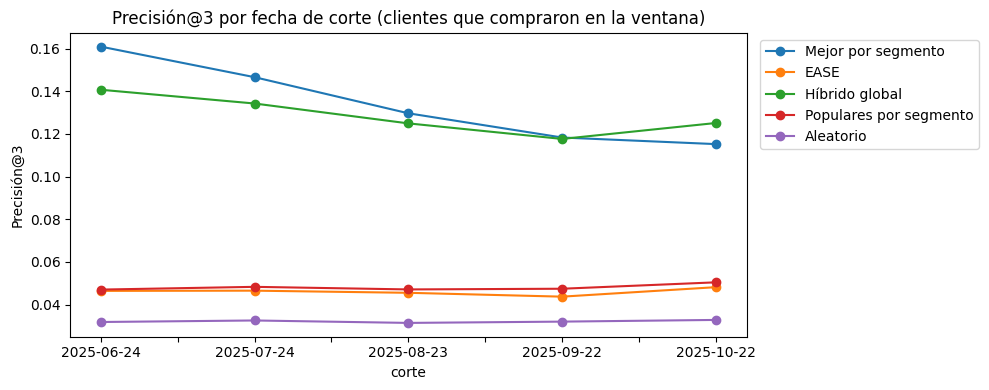

,cortes_ganados,p_valor_max
comparado_con,,
Aleatorio,5,0.0000
Híbrido global,4,1.0000
Populares por segmento,5,0.0000
SVD global,5,0.0005


metodo,Mejor por segmento,EASE + historial,EASE,kNN de productos,Historial personal,Híbrido por clúster,SVD por clúster,Híbrido global,SVD global,Populares por segmento,Populares (global),Aleatorio
segmento,,,,,,,,,,,,
VIP,0.1305,0.0991,0.0543,0.0541,0.1305,0.1009,0.0990,0.0991,0.0994,0.0554,0.0556,0.0375
Regulares,0.1030,0.1030,0.0479,0.0478,0.1379,0.1237,0.1082,0.1131,0.1007,0.0484,0.0498,0.0328
Ocasionales,0.1596,0.1596,0.0399,0.0396,0.1002,0.1541,0.1347,0.1533,0.1347,0.0431,0.0421,0.0283
Inactivos,0.1867,0.1867,0.0414,0.0403,0.1376,0.1636,0.1636,0.1694,0.1658,0.0473,0.0469,0.0304


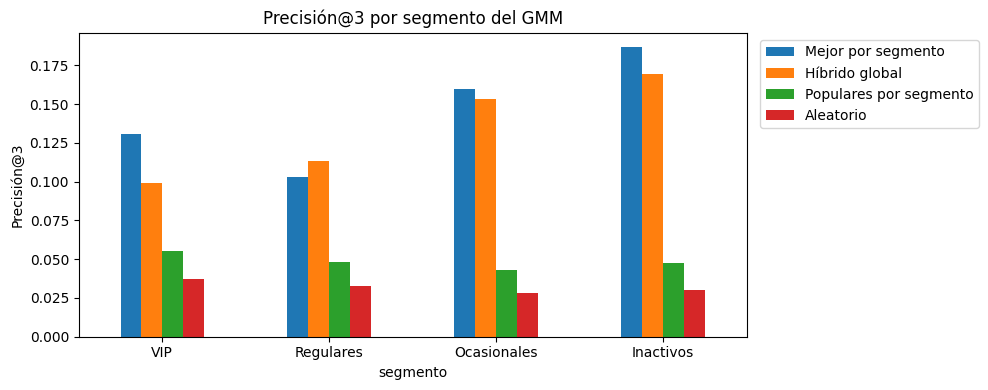

In [ ]:
# 9.2 Precisión@3 por corte
tabla_p = todos.pivot(index='corte', columns='metodo', values='Precision@3')[METODOS]
display(tabla_p)
ax = tabla_p[list(dict.fromkeys([SISTEMA_FINAL, 'EASE', 'Híbrido global', 'Populares por segmento', 'Aleatorio']))].plot(marker='o', figsize=(10, 4))
ax.set_ylabel('Precisión@3')
ax.set_title('Precisión@3 por fecha de corte (clientes que compraron en la ventana)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 9.3 ¿La mejora es estadísticamente significativa? Wilcoxon pareado sobre los aciertos de cada cliente, por corte
filas = []
for ref in [r for r in ['Híbrido global', 'SVD global', 'Populares por segmento', 'Aleatorio'] if r != SISTEMA_FINAL]:
    for c in CORTES_EVALUACION:
        x, y = aciertos_cliente[(c, SISTEMA_FINAL)], aciertos_cliente[(c, ref)]
        try:
            p = wilcoxon(x, y, alternative='greater').pvalue                # H1: el sistema final acierta más
        except ValueError:
            p = np.nan                                                      # sin diferencias entre los dos métodos
        filas.append({'comparado_con': ref, 'corte': c, 'gana': (tabla_p.loc[c, SISTEMA_FINAL] > tabla_p.loc[c, ref]), 'p_valor': p})
pruebas = pd.DataFrame(filas)
display(pruebas.groupby('comparado_con').agg(cortes_ganados=('gana', 'sum'), p_valor_max=('p_valor', 'max')))

# 9.4 Desempeño dentro de cada segmento (promedio de los cortes): global vs. por clúster
por_seg = (res[res['segmento'] != 'Todos'].groupby(['segmento', 'metodo'])['Precision@3'].mean()
           .unstack()[METODOS].loc[ORDEN_SEG])
display(por_seg)
por_seg[list(dict.fromkeys([SISTEMA_FINAL, 'Híbrido global', 'Populares por segmento', 'Aleatorio']))].plot(kind='bar', figsize=(10, 4), rot=0)
plt.ylabel('Precisión@3')
plt.title('Precisión@3 por segmento del GMM')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# 9.5 Lectura de negocio: de cada 1,000 clientes que compran en el mes, cuántos compran algo de lo recomendado
negocio = pd.DataFrame({'clientes_con_acierto_por_1000': m['Tasa_acierto'] * 1000,
                        'productos_acertados_por_1000': m['Precision@3'] * TOP_N * 1000}).loc[METODOS].round(0)
display(negocio)

,clientes_con_acierto_por_1000,productos_acertados_por_1000
metodo,,
Mejor por segmento,334.0000,402.0000
EASE + historial,321.0000,385.0000
EASE,131.0000,138.0000
kNN de productos,130.0000,138.0000
Historial personal,320.0000,379.0000
Híbrido por clúster,337.0000,398.0000
SVD por clúster,310.0000,362.0000
Híbrido global,327.0000,386.0000
SVD global,303.0000,354.0000


## 10. Sistema final: recomendaciones y campañas por cliente

In [ ]:
# 10. Sistema final (entrenado con todo el historial)
corte_final = FECHA_MAX + pd.Timedelta(days=1)
seg_f, gmm_f, scaler_f, X_f = segmentar(rfm(ventas, corte_final))           # Modelo 1 con todo el historial
seg_f['atipico'] = DBSCAN(eps=0.4, min_samples=10).fit(X_f).labels_ == -1    # atípicos
clientes_f = seg_f.index.values
ctx_f = contexto(ventas, corte_final, clientes_f, seg_f['segmento'].values, seg_f)
M_f = ctx_f['M']
S_f = puntajes_metodo(SISTEMA_FINAL, ctx_f)                                    # Modelo 2 (el ganador de la sección 9)
top_f = top_n(S_f)

# 10.1 Producto de una categoría que el cliente nunca ha comprado (apoya el KPI de variedad)
cat_prod = productos.set_index('product_id').loc[PRODUCTOS, 'category']   # categoría de cada producto
C = pd.get_dummies(cat_prod).values.astype(float)                          # producto × categoría (0/1)
compro_cat = ((M_f > 0).astype(float) @ C) > 0                              # cliente × categoría ya comprada
nueva = ~(compro_cat @ C.T > 0)                                             # cliente × producto de categoría no comprada
S_desc = puntajes_metodo('EASE', ctx_f)                                     # EASE descubre productos que el cliente no ha comprado
S_nueva = np.where(nueva, S_desc, -np.inf)
idx_nueva = S_nueva.argmax(axis=1)
tiene_nueva = np.isfinite(S_nueva.max(axis=1))

# 10.2 Campaña por segmento
CAMPANAS = {
    'VIP': 'Novedades y preventa exclusiva (sin descuentos agresivos)',
    'Regulares': 'Venta cruzada de categorías que todavía no compra',
    'Ocasionales': 'Cupón de segunda compra con los productos recomendados',
    'Inactivos': 'Campaña de reactivación con recordatorio de su categoría favorita',
}
KPI = {'VIP': 'Ticket promedio', 'Regulares': 'Variedad de productos',
       'Ocasionales': 'Recurrencia', 'Inactivos': 'Recurrencia'}

nombre_prod = productos.set_index('product_id')['product_name']
recs = seg_f[['segmento', 'prob_segmento', 'atipico'] + VARS_RFM].copy()
for j in range(TOP_N):
    recs[f'producto_{j + 1}'] = nombre_prod.loc[PRODUCTOS[top_f[:, j]]].values
recs['producto_nueva_categoria'] = np.where(tiene_nueva, nombre_prod.loc[PRODUCTOS[idx_nueva]].values, '—')
recs['campana'] = recs['segmento'].map(CAMPANAS)
recs['kpi_objetivo'] = recs['segmento'].map(KPI)
recs.index.name = 'cliente_id'

recs.to_csv('recomendaciones_danustore.csv')                                 # salida para el prototipo en Streamlit
print(f'Recomendaciones generadas para {len(recs):,} clientes -> recomendaciones_danustore.csv')
display(recs.head(10))

Recomendaciones generadas para 44,987 clientes -> recomendaciones_danustore.csv


,segmento,prob_segmento,atipico,recencia_dias,num_transacciones,gasto_total,producto_1,producto_2,producto_3,producto_nueva_categoria,campana,kpi_objetivo
cliente_id,,,,,,,,,,,,
1,Regulares,0.9884,False,4,18,"7,927.7300",Pants Product 55,Bags Product 68,Boots Product 108,—,Venta cruzada de categorías que todavía no compra,Variedad de productos
2,VIP,0.5518,False,6,23,"9,443.8000",Bags Product 68,Boots Product 109,Dresses Product 64,—,Novedades y preventa exclusiva (sin descuentos...,Ticket promedio
3,Regulares,0.7853,False,1,14,"6,866.4900",Sneakers Product 96,Sneakers Product 97,Bottoms Product 17,—,Venta cruzada de categorías que todavía no compra,Variedad de productos
4,Ocasionales,0.9431,False,35,14,"4,429.0900",Dresses Product 65,Bags Product 72,Hats Product 87,—,Cupón de segunda compra con los productos reco...,Recurrencia
5,Ocasionales,0.6160,False,74,14,"3,602.7500",Dresses Product 65,Bottoms Product 15,Bags Product 68,—,Cupón de segunda compra con los productos reco...,Recurrencia
6,Ocasionales,0.8926,False,61,11,"2,624.0400",Pants Product 47,Bottoms Product 15,Hats Product 87,—,Cupón de segunda compra con los productos reco...,Recurrencia
7,Regulares,0.9534,False,2,22,"7,504.8200",Bottoms Product 13,Bottoms Product 14,Sandals Product 115,—,Venta cruzada de categorías que todavía no compra,Variedad de productos
8,VIP,0.9878,False,21,22,"12,136.9200",Bottoms Product 17,Bottoms Product 19,Sandals Product 119,—,Novedades y preventa exclusiva (sin descuentos...,Ticket promedio
9,Regulares,0.8743,False,69,18,"8,143.9800",Boots Product 113,Sneakers Product 97,Dresses Product 61,—,Venta cruzada de categorías que todavía no compra,Variedad de productos


In [ ]:
# 10.3 Resumen de la estrategia por segmento
resumen_seg = recs.groupby('segmento').agg(clientes=('campana', 'size'),
                                            prob_media=('prob_segmento', 'mean'),
                                            gasto_medio=('gasto_total', 'mean'),
                                            atipicos=('atipico', 'sum')).loc[ORDEN_SEG]
resumen_seg['campana'] = resumen_seg.index.map(CAMPANAS)
resumen_seg['kpi_objetivo'] = resumen_seg.index.map(KPI)
display(resumen_seg)

# 10.4 Productos más recomendados en cada segmento
for s in ORDEN_SEG:
    top_s = recs.loc[recs['segmento'] == s, [f'producto_{j + 1}' for j in range(TOP_N)]].stack().value_counts().head(5)
    print(f'{s}:', ', '.join(top_s.index))

,clientes,prob_media,gasto_medio,atipicos,campana,kpi_objetivo
segmento,,,,,,
VIP,7434,0.9111,"11,282.4508",69,Novedades y preventa exclusiva (sin descuentos...,Ticket promedio
Regulares,17834,0.8680,"7,275.9610",0,Venta cruzada de categorías que todavía no compra,Variedad de productos
Ocasionales,14267,0.8852,"4,154.4771",0,Cupón de segunda compra con los productos reco...,Recurrencia
Inactivos,5452,0.9193,"4,392.9025",81,Campaña de reactivación con recordatorio de su...,Recurrencia


VIP: Sneakers Product 96, Shirts Product 43, Pants Product 47, Pants Product 54, Dresses Product 65
Regulares: Sneakers Product 96, Shirts Product 43, Pants Product 47, Pants Product 54, Dresses Product 65
Ocasionales: Sneakers Product 96, Shirts Product 43, Pants Product 47, Pants Product 54, Dresses Product 65
Inactivos: Sneakers Product 96, Shirts Product 43, Pants Product 47, Pants Product 54, Dresses Product 65


## 11. Simulador: recomendación para un cliente

In [ ]:
# 11. Simulador de recomendación
def recomendar(cliente_id):
    # devuelve segmento, confianza, 3 productos, producto de nueva categoría y campaña sugerida
    if cliente_id not in recs.index:
        return f'El cliente {cliente_id} no tiene historial de compra: se le ofrecen los 3 productos más populares.'
    r = recs.loc[cliente_id]
    return pd.Series({
        'Segmento': f"{r['segmento']} (probabilidad {r['prob_segmento']:.0%})",
        'Cliente atípico': 'Sí' if r['atipico'] else 'No',
        'Recomendación 1': r['producto_1'],
        'Recomendación 2': r['producto_2'],
        'Recomendación 3': r['producto_3'],
        'Nueva categoría': r['producto_nueva_categoria'],
        'Campaña': r['campana'],
        'KPI objetivo': r['kpi_objetivo'],
    })

# Ejemplo con un cliente de cada segmento
for s in ORDEN_SEG:
    cid = recs.index[recs['segmento'] == s][0]
    print(f'--- Cliente {cid} ---')
    print(recomendar(cid).to_string(), end='\n\n')

--- Cliente 2 ---
Segmento                                      VIP (probabilidad 55%)
Cliente atípico                                                   No
Recomendación 1                                      Bags Product 68
Recomendación 2                                    Boots Product 109
Recomendación 3                                   Dresses Product 64
Nueva categoría                                                    —
Campaña            Novedades y preventa exclusiva (sin descuentos...
KPI objetivo                                         Ticket promedio

--- Cliente 1 ---
Segmento                                Regulares (probabilidad 99%)
Cliente atípico                                                   No
Recomendación 1                                     Pants Product 55
Recomendación 2                                      Bags Product 68
Recomendación 3                                    Boots Product 108
Nueva categoría                                                   

## 12. Resumen de resultados

In [ ]:
# 12. Resumen de resultados
print(f'Segmentación (GMM, k = {K_SEGMENTOS}, covarianza {COVARIANZA}):', ', '.join(f'{s} {n:,}' for s, n in resumen_seg['clientes'].items()))
print(f'Sistema de recomendación final: {SISTEMA_FINAL}')
print('  Parámetros: EASE', P_EASE, '| historial', P_HIST, '| beta', BETA, '| kNN', P_KNN)
print('  Modelo por segmento:', RUTA)
print(f"  Mejora frente al modelo de la Evidencia 2 (Híbrido global): {mejora:+.1%} en Precisión@3")
print(f'Evaluación en {len(CORTES_EVALUACION)} cortes (clientes que compraron en los {VENTANA_DIAS} días siguientes):')
for metodo in METODOS:
    print(f"  {metodo:<24} Precisión@3 = {m.loc[metodo, 'Precision@3']:.2%} | Tasa de acierto = {m.loc[metodo, 'Tasa_acierto']:.2%}"
          f" | ROC-AUC = {m.loc[metodo, 'ROC_AUC_cliente']:.3f} | Lift vs. azar = {lift.loc[metodo, 'Lift_vs_aleatorio']:.2f}")
print(f"De cada 1,000 clientes que compran en el mes, {negocio.loc[SISTEMA_FINAL, 'clientes_con_acierto_por_1000']:.0f} compran al menos un producto recomendado"
      f" (al azar: {negocio.loc['Aleatorio', 'clientes_con_acierto_por_1000']:.0f})")
print('Archivo para el prototipo: recomendaciones_danustore.csv')

Segmentación (GMM, k = 4, covarianza spherical): VIP 7,434, Regulares 17,834, Ocasionales 14,267, Inactivos 5,452
Sistema de recomendación final: Mejor por segmento
  Parámetros: EASE {'tau': 30, 'lam': 1000.0} | historial {'tau': None} | beta 0.75 | kNN {'tau': 30}
  Modelo por segmento: {'VIP': 'Historial personal', 'Regulares': 'EASE + historial', 'Ocasionales': 'EASE + historial', 'Inactivos': 'EASE + historial'}
  Mejora frente al modelo de la Evidencia 2 (Híbrido global): +4.4% en Precisión@3
Evaluación en 5 cortes (clientes que compraron en los 30 días siguientes):
  Mejor por segmento       Precisión@3 = 13.41% | Tasa de acierto = 33.40% | ROC-AUC = 0.814 | Lift vs. azar = 4.17
  EASE + historial         Precisión@3 = 12.83% | Tasa de acierto = 32.12% | ROC-AUC = 0.809 | Lift vs. azar = 3.99
  EASE                     Precisión@3 = 4.61% | Tasa de acierto = 13.08% | ROC-AUC = 0.577 | Lift vs. azar = 1.43
  kNN de productos         Precisión@3 = 4.58% | Tasa de acierto = 13.01% 

In [ ]:
from google.colab import files
files.download("recomendaciones_danustore.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>